In [3]:
import pandas as pd
import numpy as np
import torch
import torch.nn as nn
import torch.optim as optim
import matplotlib.pyplot as plt

In [4]:
np.random.seed(23)
torch.manual_seed(23)

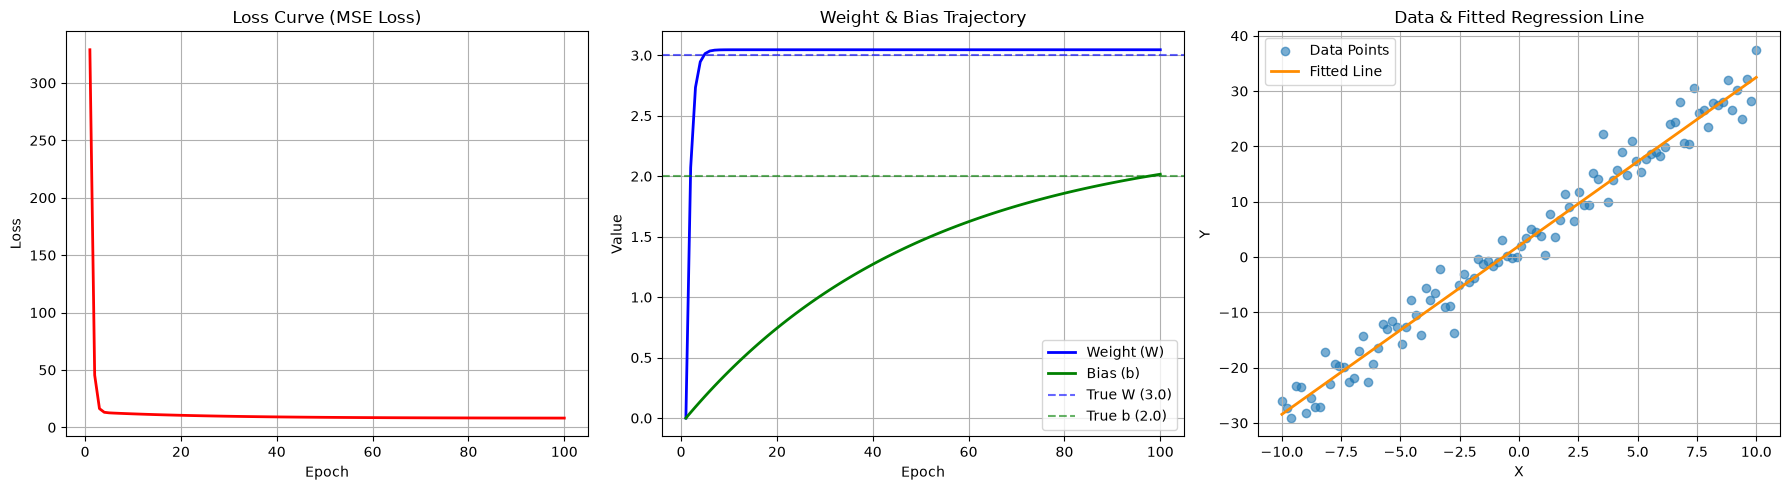

In [5]:
# create random dataset

x_data = np.linspace(-10, 10, 100).reshape(-1, 1)
noise = np.random.randn(100, 1) * 3
y_data = 3.0 * x_data + 2.0 + noise

X = torch.tensor(x_data, dtype = torch.float32)
Y = torch.tensor(y_data, dtype = torch.float32)

model = nn.Linear(1,1)

nn.init.constant_(model.weight, 0.0)
nn.init.constant_(model.bias, 0.0)

# setting Loss Function
criterion = nn.MSELoss()

# setting optimizer
optimizer = optim.SGD(model.parameters(), lr = 0.01)

# model learning / record Loss, Weight
epochs = 100
history = []

for epoch in range(epochs):
    predictions = model(X)
    loss = criterion(predictions, Y)

    current_w = model.weight.item()
    current_b = model.bias.item()
    current_loss = loss.item()

    history.append({
        'epoch' : epoch + 1,
        'loss' : current_loss,
        'weight' : current_w,
        'bias' : current_b,
    })

    optimizer.zero_grad()
    loss.backward()
    optimizer.step()

df_history = pd.DataFrame(history)

# Visualization

fig, axes = plt.subplots(1, 3, figsize = (18, 5))

# 그래프 1: 에폭에 따른 오차(Loss) 변화
axes[0].plot(df_history['epoch'], df_history['loss'], color='red', linewidth=2)
axes[0].set_title('Loss Curve (MSE Loss)')
axes[0].set_xlabel('Epoch')
axes[0].set_ylabel('Loss')
axes[0].grid(True)

# 그래프 2: 에폭에 따른 가중치(Weight & Bias) 변화
axes[1].plot(df_history['epoch'], df_history['weight'], label='Weight (W)', color='blue', linewidth=2)
axes[1].plot(df_history['epoch'], df_history['bias'], label='Bias (b)', color='green', linewidth=2)
axes[1].axhline(y=3.0, color='blue', linestyle='--', alpha=0.6, label='True W (3.0)')
axes[1].axhline(y=2.0, color='green', linestyle='--', alpha=0.6, label='True b (2.0)')
axes[1].set_title('Weight & Bias Trajectory')
axes[1].set_xlabel('Epoch')
axes[1].set_ylabel('Value')
axes[1].legend()
axes[1].grid(True)

# 그래프 3: 실제 데이터와 최종 회귀선
axes[2].scatter(x_data, y_data, alpha=0.6, label='Data Points')
final_pred = model(X).detach().numpy()
axes[2].plot(x_data, final_pred, color='darkorange', linewidth=2, label='Fitted Line')
axes[2].set_title('Data & Fitted Regression Line')
axes[2].set_xlabel('X')
axes[2].set_ylabel('Y')
axes[2].legend()
axes[2].grid(True)

plt.tight_layout()
plt.show()

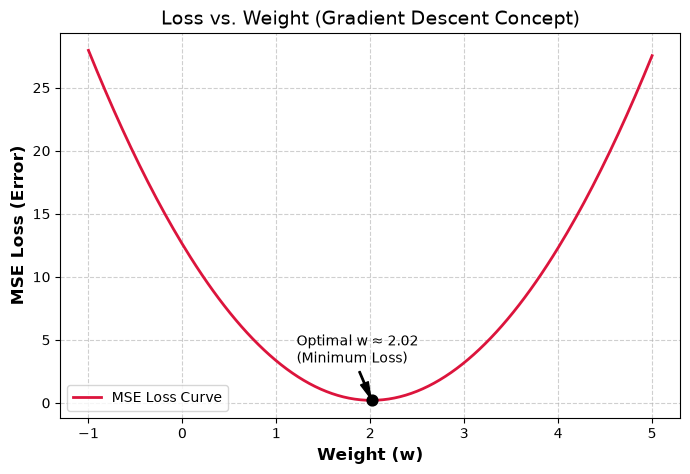

In [6]:
import numpy as np
import matplotlib.pyplot as plt

# 1. 가상 데이터 생성 (정답 함수: y = 2x)
np.random.seed(42)
X = np.linspace(-3, 3, 100)
y_true = 2 * X + np.random.normal(0, 0.5, size=100)

# 2. 가중치(w) 범위 설정 (X축)
w_range = np.linspace(-1, 5, 200)
mse_losses = []

# 3. 각 가중치 w에 따른 MSE Loss 계산 (Y축)
for w in w_range:
    y_pred = w * X
    loss = np.mean((y_true - y_pred) ** 2)
    mse_losses.append(loss)

# 4. 그래프 시각화
plt.figure(figsize=(8, 5))
plt.plot(w_range, mse_losses, label='MSE Loss Curve', color='crimson', linewidth=2)

# 최적 가중치(최솟점) 표시
min_idx = np.argmin(mse_losses)
best_w = w_range[min_idx]
min_loss = mse_losses[min_idx]

plt.scatter([best_w], [min_loss], color='black', zorder=5, s=60)
plt.annotate(f'Optimal w ≈ {best_w:.2f}\n(Minimum Loss)', 
             xy=(best_w, min_loss), 
             xytext=(best_w - 0.8, min_loss + 3),
             arrowprops=dict(facecolor='black', shrink=0.05, width=1, headwidth=6))

# 축 라벨 및 디자인 설정
plt.xlabel('Weight (w)', fontsize=12, fontweight='bold')
plt.ylabel('MSE Loss (Error)', fontsize=12, fontweight='bold')
plt.title('Loss vs. Weight (Gradient Descent Concept)', fontsize=14)
plt.grid(True, linestyle='--', alpha=0.6)
plt.legend()
plt.show()

# Reference : ChatGPT
---

### Actual Data 
$ Y = 3x + 2 $

### Hypothesis 
$ \hat{Y} = wx + b $

### Loss Function 

MSE($w, b$) = $ \frac{1}{N} \sum^{n}_{i = 1} (\hat{y} - y)^2 $

### Update Params 

$ w = w - \alpha \frac{\partial L}{\partial w} $ 

$ b = b - \alpha \frac{\partial L}{\partial b} $

- $\alpha : \text{Learning Rate}$
- $ \text{L : Loss} $



In [ ]:
import numpy as np

np.random.seed(8)

x = np.linspace(0, 10, 1000).reshape(-1, 1)
# np.linspace(start, end, num_of_value)
noise = np.random.normal(loc = 0, scale = 1, size = x.shape)
# np.random.normal(loc = mean, scale = std, size = num_of_value)
y = 3 * x + 10 + noise

#weight
w = 0.0
#bias
b = 0.0

learning_rate = 0.01
epochs = 10000




